# Learn the GlobalForms spec and metrics

**A 30–45 minute workshop for participants implementing a submission.**

Start with a blank page, describe its meaning, predict a score, then ask whether
that score captures what matters. By the end you should be able to:

1. Validate a recovery spec and distinguish regions, fields and source evidence.
2. Explain how a recovery error can affect several Track A components.
3. Compute TP / FP / FN, F1 and Track B answer accuracy on worked examples.
4. Distinguish missing information, inactive fields and omitted supplied answers.
5. Use oracle versus recovered-spec completion to diagnose an error.
6. Diagnose a submission and identify the pilot's current coverage limits.

**How to use this notebook:** pause at each **Predict** prompt. Write down an
answer before expanding **Reveal**. Saved outputs let you read without running
Python; to experiment, run from the repository root with the notebook extra and
Poppler installed. Choose **Restart Kernel and Run All Cells** first.

```sh
uv sync --locked --extra notebook
uv run --locked --extra notebook jupyter lab GlobalForms-teaching.ipynb
```

Every example below uses the bundled synthetic fixtures and the existing
`globalforms.metrics` scorer. Execution makes no model calls or downloads.
This teaches the current **pilot**, whose schema and scoring policy remain
provisional. The [fixture guide](GlobalForms-metric-pilot.ipynb) supplies the
complete case catalogue. Proposed extensions appear at the end.


In [1]:
from copy import deepcopy
from html import escape
import json
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display

from globalforms import FormSpec, PredictionFormSpec
from globalforms.fixtures import load_review, read_page
from globalforms.metrics import SCORER_VERSION, f1, track_a, track_b
from globalforms.metrics.alignment import align
from globalforms.notebook_review import show_constraints, show_rule_effects
from globalforms.overlays import compare_layer, draw_layer, page_axes, page_marks

incident = load_review("fixtures/incident/review.json")
locker = load_review("fixtures/locker/review.json")
length = load_review("fixtures/length/review.json")
gold = incident.reference.model_dump(exclude_unset=True)
paper, page_size = read_page(incident)

# Display helpers only. All scores come from the imported production scorer.
def table(headers, rows):
    head = "".join(f"<th>{escape(str(h))}</th>" for h in headers)
    body = "".join("<tr>" + "".join(f"<td>{escape(str(v))}</td>" for v in row)
                   + "</tr>" for row in rows)
    return f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"

def reveal(title, body):
    display(HTML("<details><summary>Reveal explanation and computed scores</summary>"
                 + f"<h4>{escape(title)}</h4>{body}</details>"))

def percent(counts):
    value = f1(counts)
    return f"{value:.1%}" if value is not None else "No support"

def completion_row(title, grade):
    correct, denominator = grade["value"]
    coverage = "/".join(map(str, grade["coverage"]))
    return [title, f"{correct}/{denominator}", coverage,
            "Pass" if grade["complete"][0] else "Fail"]

print(f"Schema: {gold['schemaVersion']} · Scorer: {SCORER_VERSION}")
print("Three synthetic fixtures loaded locally. No private data is used.")


Schema: pilot-2 · Scorer: pilot-metrics-2
Three synthetic fixtures loaded locally. No private data is used.


## 0. What your implementation produces

| Task | Your implementation receives | Your implementation returns | Local interface |
|---|---|---|---|
| A: recovery | The blank source form | A spec containing fields, regions, evidence, sections, roles, rules and validations | `PredictionFormSpec` validates the current producer format; `track_a` scores it against a reference |
| B-oracle | Scenario facts and the reviewed spec | Entries keyed by that spec's field IDs | `track_b(submitted, expected, reference)` |
| B-end-to-end | Scenario facts and a recovered spec | Entries keyed by the recovered spec's field IDs | `track_b(submitted, expected, reference, recovered)` |

The examples expose references and expected answers for learning. An evaluated
system must not receive the hidden reference or expected answers. The grader
takes them separately from your output. This notebook demonstrates pilot Python
contracts; the final competition upload format and service are not frozen here.

**Track A:** `PredictionFormSpec` supplies the current `pilot-2` producer schema.
`FormSpec` additionally reads archived schema versions. Validate before scoring:
unknown properties, invalid references and malformed option ownership can fail
conformance before they become a score. Conformance alone does not prove that
a claim is supported by the source.

**Track B:** each submitted field has exactly one `value` or `status` entry.
The allowed input statuses are `missing`, `conflicting` and `invalid`.

```json
{"name": {"value": "Alex"}, "reviewer": {"status": "missing"}}
```

Use the field IDs from the supplied spec. Preserve identifiers as strings when
leading zeroes matter. In this pilot, ordinary answer strings are compared
after case-folding and whitespace normalization; dates use ISO calendar values;
choice values must match their option keys exactly. Follow each fixture's
reviewed expected-answer policy rather than adding your own coercions.


In [2]:
# In your adapter, read your candidate JSON instead of this worked fixture.
candidate_json = Path("fixtures/incident/predictions/fields.json").read_text()
candidate = PredictionFormSpec.model_validate_json(candidate_json)
producer_schema = PredictionFormSpec.model_json_schema()
schema_path = Path("output/teaching/prediction-form-spec.schema.json")
schema_path.parent.mkdir(parents=True, exist_ok=True)
schema_path.write_text(json.dumps(producer_schema, indent=2) + "\n")
print(f"Producer conformance passed: {candidate.schemaVersion}")
print(f"Current producer JSON Schema exported to {schema_path}")
print("This fixture has valid structure and intentionally wrong option ownership.")


Producer conformance passed: pilot-2
Current producer JSON Schema exported to output/teaching/prediction-form-spec.schema.json
This fixture has valid structure and intentionally wrong option ownership.


## 1. Two tasks, two questions

**Track A — recovery:** given a blank form, recover its machine-readable spec.
**Track B — completion:** given scenario facts and a spec, return values or
explicit input statuses for the appropriate fields.

| Spec layer | What it means | Incident example |
|---|---|---|
| `regions` | Where an answer belongs | The writable name box |
| `fields` | What answer that space represents | Applicant name; Yes/No with option ownership |
| `evidence` / `evidenceIds` | Source supporting a claim | A printed label, heading or instruction |
| `sections` and roles | Grouping and completion responsibility | Applicant versus Business Office |
| `rules` | When a target applies or is required | If Yes, describe the incident |
| `validations` | Additional document-supported constraints | The printed YYYY-MM-DD date mask |

**Predict 1:** is the printed “Applicant name” label an answer region? Could
correct answer boxes still be paired with the wrong meaning?


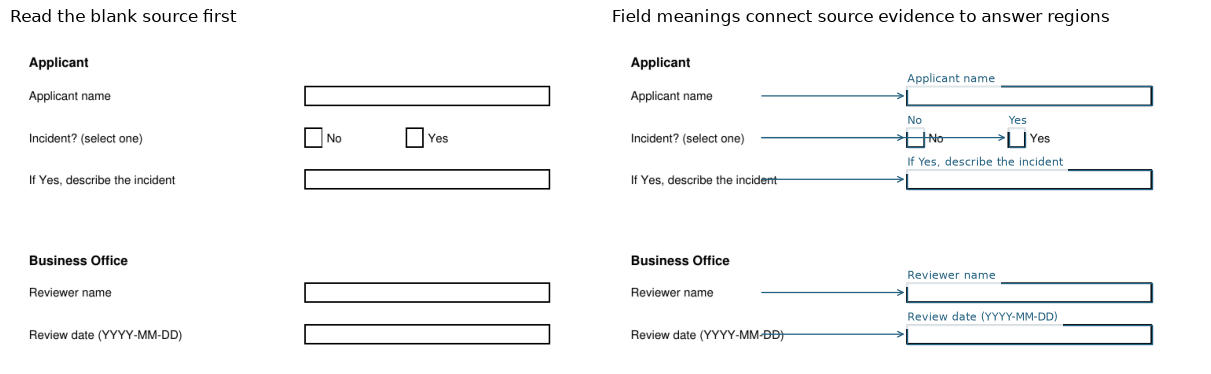

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
for ax in axes:
    page_axes(ax, page_size, image=paper, crop=incident.crop)
axes[0].set_title("Read the blank source first", loc="left")
draw_layer(axes[1], page_marks(incident.reference, incident.page), "fields")
axes[1].set_title("Field meanings connect source evidence to answer regions", loc="left")
plt.show()

field = gold["fields"]["name"]
excerpt = {"field": field,
           "answer_region": gold["regions"][field["regions"][0]],
           "source_evidence": gold["evidence"][field["evidenceIds"][0]]}
reveal("different jobs for evidence and answer regions",
       "<p>The label is evidence; the writable space is the answer region. "
       "Correct boxes alone cannot establish correct meanings or option ownership. "
       "Page numbers are one-based. Boxes use top-left x, y, width, height in PDF points.</p>"
       + "<pre>" + escape(json.dumps(excerpt, indent=2)) + "</pre>")


## 2. Read a score as a set of claims

A **true positive (TP)** is a matched, correct claim. A **false positive (FP)**
is a predicted claim that does not match the reference. A **false negative
(FN)** is a reference claim that was missed. The unit depends on the component:
a region, a joint field definition, a membership or a rule edge.

**F1 = 2 × TP / (2 × TP + FP + FN).** Replacing a correct claim with a wrong
one can create both one FP and one FN. A missing membership creates an FN
without necessarily creating an FP.

**Predict 2:** the incident has six answer regions but five logical fields.
Keep all boxes in place and swap which box means Yes and No. Which scores
fall: geometry, joint fields, or both? Compute field F1 if four fields pass
and the fifth is wrong.


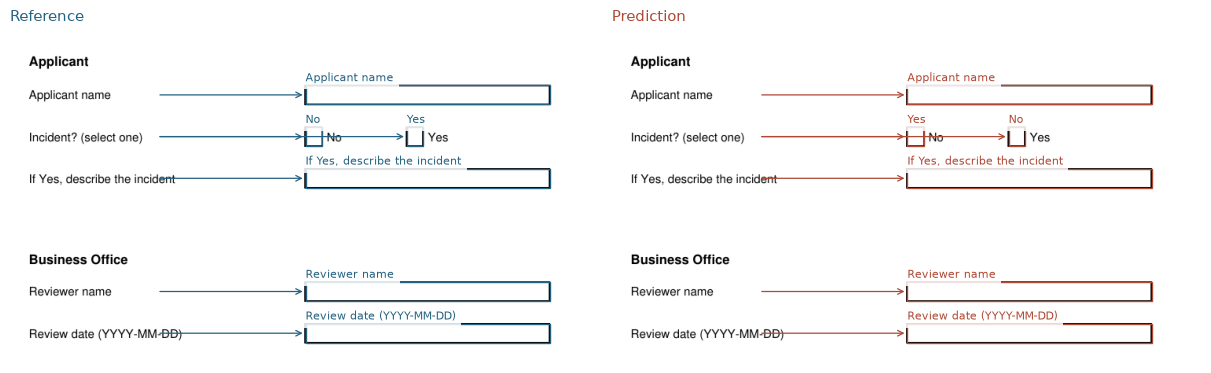

Component,TP,FP,FN,F1
geometry,6,0,0,100.0%
fields,4,1,1,80.0%


In [4]:
ownership_case = next(c for c in incident.track_a if c.layer == "fields")
swapped = ownership_case.spec.model_dump(exclude_unset=True)
components, diagnostics = track_a(swapped, gold, default_role=incident.default_role)
fig = compare_layer(page_marks(incident.reference, 1), page_marks(ownership_case.spec, 1),
                    "fields", page_size, image=paper, crop=incident.crop)
plt.show()
assert components["geometry"] == (6, 0, 0)
assert components["fields"] == (4, 1, 1)
reveal("perfect geometry, 80% joint-field F1",
       table(["Component", "TP", "FP", "FN", "F1"],
             [[key, *components[key], percent(components[key])]
              for key in ("geometry", "fields")])
       + "<p>The Yes/No field owns two boxes. Swapping their meanings leaves all six "
       "regions matched, but fails the joint field check: 8 / (8 + 1 + 1) = 80%. "
       "The joint check covers type, label, option ownership and cardinality.</p>")


## 3. One source error can propagate

The pilot first matches answer regions and then matches fields by their
owned regions. Local field IDs need not agree. A field whose grounding cannot
match may also lose its section, role and rule correspondence.

The current region matcher requires overlap covering **at least 50% of the
reference box and 20% of the predicted box**, on the same page. These are
implemented pilot thresholds awaiting calibration. They are not an IoU score.

**Predict 3:** move only the Yes box 24 PDF points to the right so it no longer
overlaps. Does the geometry error stay confined to the geometry row?


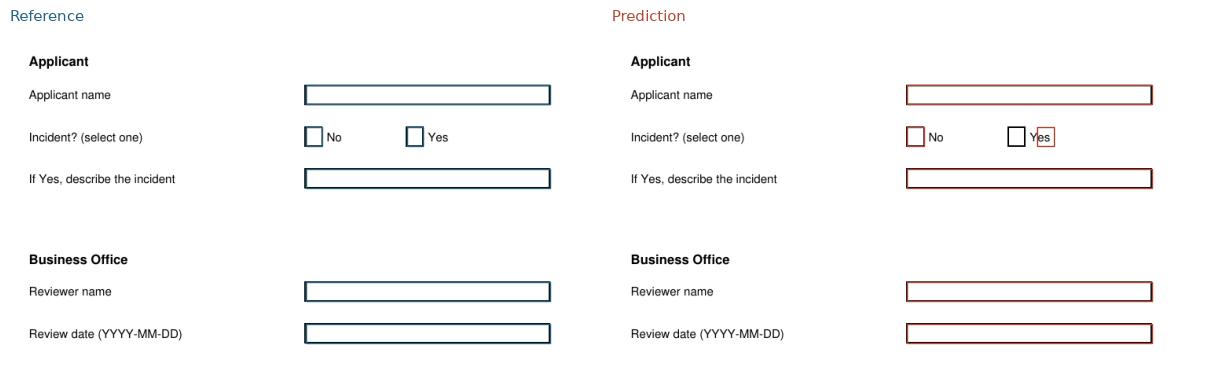

Component,Clean TP/FP/FN,Shifted TP/FP/FN,Shifted F1
geometry,"(6, 0, 0)","(5, 1, 1)",83.3%
fields,"(5, 0, 0)","(4, 1, 1)",80.0%
sections,"(5, 0, 0)","(4, 1, 1)",80.0%
roles,"(5, 0, 0)","(4, 1, 1)",80.0%
rules,"(1, 0, 0)","(0, 1, 1)",0.0%


In [5]:
geometry_case = next(c for c in incident.track_a if c.layer == "geometry")
displaced = geometry_case.spec.model_dump(exclude_unset=True)
clean, _ = track_a(gold, gold, default_role=incident.default_role)
shifted, _ = track_a(displaced, gold, default_role=incident.default_role)
fig = compare_layer(page_marks(incident.reference, 1), page_marks(geometry_case.spec, 1),
                    "geometry", page_size, image=paper, crop=incident.crop)
plt.show()
assert shifted["geometry"] == (5, 1, 1)
assert shifted["rules"] == (0, 1, 1)
reveal("the correspondence error reaches every ranked component here",
       table(["Component", "Clean TP/FP/FN", "Shifted TP/FP/FN", "Shifted F1"],
             [[key, clean[key], shifted[key], percent(shifted[key])] for key in clean])
       + "<p>The incident choice loses field alignment. Its dependent claims then lose "
       "correspondence too. An error matrix can therefore flag several rows for one "
       "planted mistake; those flags are not independent mistake counts.</p>")


## 4. Ownership, applicability and requiredness answer different questions

Roles resolve from the field, then the nearest assigned section, then the
evaluator's optional default. On this fixture the default is Applicant and
the Office section overrides it with Business Office.

**Applicability:** does the target apply on this branch? **Requiredness:**
does an active target need an answer for submission? An unanswered controller
leaves these effects unresolved; the current Track B cases provide reviewed,
resolved expectations rather than asking the grader to infer the branch.

**Predict 4:** reverse only the applicability rule from Yes to No, leaving the
requiredness rule intact. Should both rule scores fall?


In [6]:
show_rule_effects(incident.reference)
rule_case = next(c for c in incident.track_a if c.layer == "rules")
ranked, diagnostic = track_a(rule_case.spec.model_dump(exclude_unset=True), gold,
                             default_role=incident.default_role)
assert ranked["rules"] == (0, 1, 1)
assert diagnostic["requiredness"] == (1, 0, 0)
reveal("applicability falls; requiredness remains correct",
       table(["Current policy", "TP", "FP", "FN", "F1"],
             [["Ranked applicability", *ranked["rules"], percent(ranked["rules"])],
              ["Diagnostic requiredness", *diagnostic["requiredness"],
               percent(diagnostic["requiredness"])]])
       + "<p>The two effects are distinct records. Requiredness and validations are "
       "diagnostics in the current pilot. The five ranked components are geometry, "
       "joint fields, section memberships, roles and applicability rules. A weighted "
       "Track A headline remains undecided.</p>")


Incident? (select one) → If Yes, describe the incident (applicable)
  No → inactive
  Yes → active
  Unanswered → unresolved
Incident? (select one) → If Yes, describe the incident (required)
  No → no requirement from this rule
  Yes → required when active
  Unanswered → unresolved


Current policy,TP,FP,FN,F1
Ranked applicability,0,1,1,0.0%
Diagnostic requiredness,1,0,0,100.0%


## 5. Recover what the document supports

A field type does not establish every possible constraint. “Pickup date”
identifies a date field; a printed “YYYY-MM-DD” additionally establishes a mask.
Likewise, the three identifier fields below carry different evidence:

- An ordinary box supplies no stated six-character constraint.
- Six character cells support a maximum of six in this fixture.
- “Exactly six digits” supplies minimum six, maximum six and an ASCII digit alphabet.

**Predict 5:** a candidate predicts only a maximum of six for all three fields.
Count distinct supported claims. How many TP, FP and FN does it receive?
Would `ABCDEF` satisfy the six-cell field? The exactly-six-digits field?


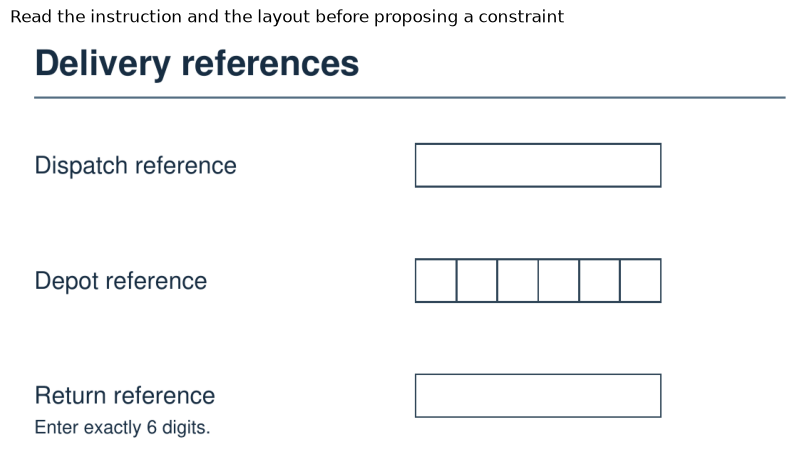

Field,Constraint,Evidence,12,ABCDEF,001234,1234567
Dispatch reference,None,,Pass,Pass,Pass,Pass
Depot reference,≤ 6 chars,six_cells,Pass,Pass,Pass,Fail
Return reference,"exactly 6 chars, digits 0–9",digits_instruction,Fail,Fail,Pass,Fail


In [7]:
length_paper, length_size = read_page(length)
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
page_axes(ax, length_size, image=length_paper, crop=length.crop)
ax.set_title("Read the instruction and the layout before proposing a constraint", loc="left")
plt.show()
length_gold = length.reference.model_dump(exclude_unset=True)
_, constraint_counts = track_a(length.track_a[0].spec.model_dump(exclude_unset=True), length_gold)
counts = constraint_counts["validation"]
assert counts == (2, 1, 2)
assert not length.reference.failed_validations("cells", "ABCDEF")
assert length.reference.failed_validations("digits", "ABCDEF")
reveal("2 TP, 1 FP, 2 FN: 57.1% validation F1",
       "<p>TP: the maximum on cells and the maximum on digits. FP: the unsupported "
       "maximum on the plain box. FN: the digits minimum and digit alphabet. "
       "F1 = 4 / (4 + 1 + 2). Splitting equivalent bounds into separate records does "
       "not change the claims. ABCDEF fits the six cells but violates the digit alphabet.</p>")
# Run this existing fixture view to inspect the constraints and supplied-string probes.
show_constraints(length)


## 6. The same blank can earn different credit

Track B compares the submission with **reviewed expected entries for this
scenario**. The grader does not read the narrative or independently decide
whether a missing answer was available.

Each correct expected value or status earns one point. An absent key can
substitute for an expected `{"status": "missing"}`. It cannot substitute for
a supplied value, an invalid status or a conflicting status. A `null` entry is
not the same as an absent key.

**Predict 6:** both scenarios below receive exactly the same submission, with
no reviewer entry. Predict answer accuracy, explicit coverage and case pass
for each. Can full answer credit coexist with incomplete submission readiness?


In [8]:
accepted, penalized = incident.track_b[:2]
assert accepted.submitted == penalized.submitted
for case in (accepted, penalized):
    display(Markdown(f"**{case.title}:** {case.scenario}"))
display(Markdown("**Identical submitted entries**\n\n```json\n"
                 + json.dumps(accepted.submitted, indent=2) + "\n```"))


**Accepted omission:** Alex reports a broken latch. The review date is 29 February 2004. The reviewer is unnamed.

**Penalized omission:** Alex reports a broken latch. Sam reviews the incident on 29 February 2004.

**Identical submitted entries**

```json
{
  "name": {
    "value": "Alex"
  },
  "review_date": {
    "value": "2004-02-29"
  },
  "incident": {
    "value": "Yes"
  },
  "details": {
    "value": "Broken latch"
  }
}
```

In [9]:
omission_grades = [track_b(c.submitted, c.expected, gold) for c in (accepted, penalized)]
assert [g["value"] for g in omission_grades] == [(5, 5), (4, 5)]
reveal("5/5 versus 4/5, even though both have 4/5 explicit coverage",
       table(["Case", "Answer accuracy", "Coverage", "Case"],
             [completion_row(c.title, g) for c, g in zip((accepted, penalized), omission_grades)])
       + "<p>The first expected reviewer is missing; the second is Sam. Both submissions "
       "explicitly cover four fields. The accepted omission earns the fifth point. "
       "A Track B case pass records faithful handling of these facts; it does not certify "
       "that every document obligation has been fulfilled for submission.</p>")


Case,Answer accuracy,Coverage,Case
Accepted omission,5/5,4/5,Pass
Penalized omission,4/5,4/5,Fail


## 7. A correct answer can still be an extra entry

**Answer accuracy = correct expected entries / (expected entries + extra entries).**
Extras include entries in inactive fields and entries without a reference match.
A case passes only when all expected entries are correct and there are no extras.

**Predict 7:** on the No branch, the four expected entries are correct, but the
system writes an incident description too. Is that 4/4, 4/5 or 5/5? What if
all five expected entries on the Yes branch are correct and an unknown case
number is added? Does having a box for the unknown field remove its penalty?


In [10]:
extra_cases = incident.track_b[2:]
extra_grades = [track_b(c.submitted, c.expected, gold,
                        c.spec.model_dump(exclude_unset=True) if c.spec else None)
                for c in extra_cases]
assert [g["value"] for g in extra_grades] == [(4, 5), (5, 6), (5, 6)]
reveal("inactive leakage is 4/5; either unknown entry makes 5/6",
       table(["Case", "Answer accuracy", "Coverage", "Case"],
             [completion_row(c.title, g) for c, g in zip(extra_cases, extra_grades)])
       + "<p>Every row fails complete-case success. A correct value has to belong to "
       "an expected field. A predicted box can show where an unsolicited value was "
       "written; it does not make the field legitimate. Coverage alone misses these errors.</p>")


Case,Answer accuracy,Coverage,Case
Inactive entry,4/5,4/4,Fail
Unknown entry with a predicted region,5/6,5/5,Fail
Unknown entry without a region,5/6,5/5,Fail


## 8. Separate recovery errors from completion errors

**B-oracle** uses the reviewed spec and its field IDs. **B-end-to-end** uses a
recovered spec, then aligns its fields to the reference through answer geometry.
Compare the modes with a deliberate input contract for each: an oracle
submission uses reference IDs; a recovered submission uses recovered IDs.

The locker candidate calls the identifier `slot`; the reference calls it
`locker`. The original answer region still matches.

**Predict 8:** does renaming the local field ID make the recovered completion
wrong? If the recovered box moves off target, can the correct text rescue it?


In [11]:
collection = locker.track_b[0]
locker_gold = locker.reference.model_dump(exclude_unset=True)
recovered = collection.spec.model_dump(exclude_unset=True)
_, bound = align(recovered, locker_gold)
display(Markdown("**Recovered → reference field correspondence:** `" + str(bound) + "`"))
oracle_grade = track_b(collection.expected, collection.expected, locker_gold)
recovered_grade = track_b(collection.submitted, collection.expected, locker_gold, recovered)

displaced_locker = deepcopy(recovered)
slot_region = displaced_locker["fields"]["slot"]["regions"][0]
displaced_locker["regions"][slot_region]["bbox"][0] += 170
FormSpec.model_validate(displaced_locker)
failed_grounding = track_b(collection.submitted, collection.expected, locker_gold, displaced_locker)
assert oracle_grade["value"] == recovered_grade["value"] == (2, 2)
assert failed_grounding["value"] == (1, 3)
reveal("a renamed ID passes; a lost destination does not",
       table(["Run", "Answer accuracy", "Coverage", "Case"],
             [completion_row("Oracle, reference IDs", oracle_grade),
              completion_row("Recovered, slot aligned to locker", recovered_grade),
              completion_row("Same text, displaced slot box", failed_grounding)])
       + "<p>After displacement, pickup remains correct, locker is missing and slot is "
       "unmatched: 1 / (2 expected + 1 extra) = 1/3. This controlled contrast locates "
       "the failure in grounding. It is a synthetic diagnostic, not a measured model result. "
       "Passing recovered IDs to oracle mode would be a contract mismatch.</p>")


**Recovered → reference field correspondence:** `{'pickup': 'pickup', 'slot': 'locker'}`

Run,Answer accuracy,Coverage,Case
"Oracle, reference IDs",2/2,2/2,Pass
"Recovered, slot aligned to locker",2/2,2/2,Pass
"Same text, displaced slot box",1/3,1/2,Fail


## 9. Learn what a score cannot tell you

**Predict 9:** replace the applicant-name field's evidence citation with the
office heading, preserving all answer boxes and other properties. Will the
schema reject the wrong citation? Will a ranked score change?

Also consider a reference and candidate with no rules at all. Is a rule F1
of 100% justified, or is there no positive support to score?


In [12]:
wrong_evidence = deepcopy(gold)
wrong_evidence["fields"]["name"]["evidenceIds"] = ["office_heading"]
FormSpec.model_validate(wrong_evidence)
assert track_a(wrong_evidence, gold, default_role=incident.default_role) == track_a(
    gold, gold, default_role=incident.default_role)
assert f1((0, 0, 0)) is None
reveal("valid references and unchanged scores can still hide bad evidence",
       "<p>The evidence ID exists, so reference validation passes. The current scorer "
       "does not assess evidence location or relevance. The claim still needs source review. "
       "With no TP, FP or FN, F1 is undefined and displayed as no support. Pool component "
       "counts across forms before computing F1; do not turn unsupported cases into perfect scores.</p>")


## 10. Try a change and explain its effect

Change `YES_SHIFT` below to `0`, `6`, `12` or `24`, then rerun this cell.
Before doing so, predict which components change and whether the box crosses
the matching threshold. This cell always starts from a fresh copy of the
reference, so experiments do not modify the fixture or earlier lessons.

**Explain to a partner:** why can a small movement leave F1 unchanged while a
larger movement changes several rows at once? Does either result prove the
threshold matches human judgments?


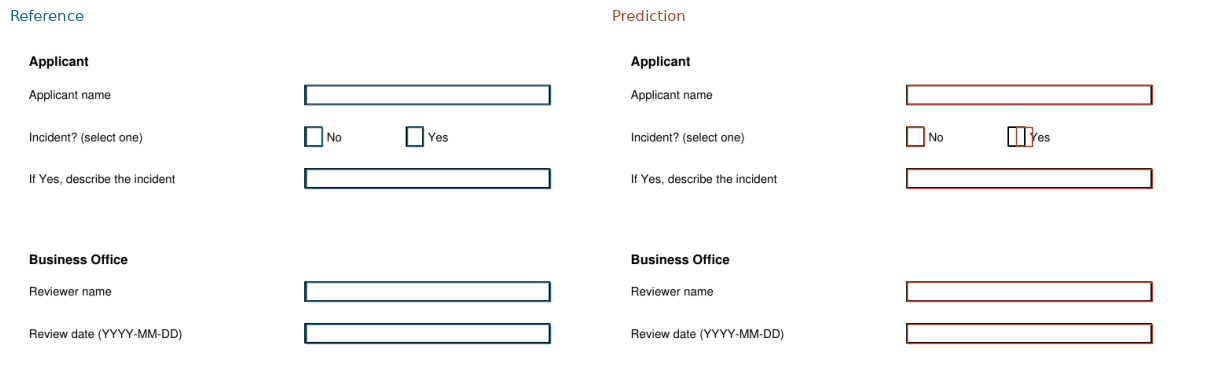

Component,TP,FP,FN,F1
geometry,6,0,0,100.0%
fields,5,0,0,100.0%
sections,5,0,0,100.0%
roles,5,0,0,100.0%
rules,1,0,0,100.0%


In [13]:
YES_SHIFT = 6  # PDF points to the right; try 0, 6, 12 or 24.

experiment = deepcopy(gold)
experiment["regions"]["incident_1"]["bbox"][0] += YES_SHIFT
experiment_spec = FormSpec.model_validate(experiment)
experiment_counts, _ = track_a(experiment, gold, default_role=incident.default_role)
fig = compare_layer(page_marks(incident.reference, 1), page_marks(experiment_spec, 1),
                    "geometry", page_size, image=paper, crop=incident.crop)
plt.show()
display(HTML(table(["Component", "TP", "FP", "FN", "F1"],
                   [[key, *value, percent(value)] for key, value in experiment_counts.items()])))


## Submission checklist and remaining policy decisions

Before evaluating a candidate, check that:

- Your recovery output validates against the current producer schema and has
  resolvable source evidence, regions, field/option ownership and rule targets.
- Your coordinates use the declared PDF frame and page numbers, with the
  original source geometry preserved through any rendering transforms.
- Your completion entries use the correct spec's IDs, values or allowed input
  statuses; inactive and unsolicited fields stay out of the output.
- You inspect component counts and oracle/end-to-end differences, as well as
  answer accuracy, explicit coverage and complete-case success.
- You record the schema and scorer versions with your local results.

The implemented examples establish scorer behavior. They do not establish
annotation accuracy or agreement with independent human judgments. Three
published briefs contain **proposed extensions**, which the lessons above
do not implement:

- [Roles](docs/discussion/role-evaluation.md): separate actor assignments from
  printed names, including anonymous actors. The current pilot uses role strings.
- [Validations](docs/discussion/validation-strategy.md): versioned tool calls
  and independently tested unfamiliar rules. The current pilot has fixed kinds.
- [Supporting documents](docs/discussion/supporting-documents.md): document
  alternatives, jointly required parts and missing-document reporting. The
  current field scorer does not implement that attachment contract.

Further open decisions include a weighted Track A headline, calibrated matching
thresholds, evidence scoring, split/merge alignment, broader answer normalization,
unresolved branches and failed submissions. The richer native annotation draft
and the smaller `pilot-2` fixture schema are distinct contracts.

**Exit ticket — answer in your own words:**

1. Give an example with perfect geometry and incorrect field meaning.
2. Explain how a blank can earn credit without completing a form for submission.
3. Compute a case with five correct expected answers and one extra entry.
4. Explain what oracle versus end-to-end completion isolates.
5. Name a source claim the current score does not verify, and how you would review it.

For a facilitated session, let participants predict independently, compare answers,
reveal the scores, then record disagreements with the metric. Assign an owner
and a concrete test to each unresolved policy question. Use the
[fixture guide](GlobalForms-metric-pilot.ipynb) to explore the remaining cases.
